# Weather and Crash Forecast (Viz 3 and ML 2)

**Author: Yaswin Chebrolu**

**Question:** Does weather change *how many* crashes happen (and how severe they are)? This tests **H3: bad weather raises crash counts but not severity.**

**What this notebook does**
1. Loads the team's cleaned crash file.
2. Downloads daily Chicago weather and joins it to daily crash counts.
3. **ML 2:** trains models to predict daily crash counts and compares them to baselines.
4. **Viz 3:** crash counts and severe-crash rate for each weather condition.

## 1. Setup

In [35]:
# If a library is missing, run in a terminal:  pip install pandas numpy matplotlib seaborn scikit-learn requests
import os
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

sns.set_theme(style="whitegrid")

## 2. Load the cleaned crash data

In [36]:
# Change this path to wherever you saved Salwa's cleaned_crashes.csv.gz
DATA_PATH = "../data/cleaned_crashes.csv.gz"

df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = df.columns.str.lower()      # makes column names consistent
print(df.shape)
print(df.columns.tolist())

(968596, 53)
['crash_record_id', 'crash_date_est_i', 'crash_date', 'posted_speed_limit', 'traffic_control_device', 'device_condition', 'weather_condition', 'lighting_condition', 'first_crash_type', 'trafficway_type', 'lane_cnt', 'alignment', 'roadway_surface_cond', 'road_defect', 'report_type', 'crash_type', 'intersection_related_i', 'not_right_of_way_i', 'hit_and_run_i', 'damage', 'date_police_notified', 'prim_contributory_cause', 'sec_contributory_cause', 'street_no', 'street_direction', 'street_name', 'beat_of_occurrence', 'photos_taken_i', 'statements_taken_i', 'dooring_i', 'work_zone_i', 'work_zone_type', 'workers_present_i', 'num_units', 'crash_month', 'most_severe_injury', 'injuries_total', 'injuries_fatal', 'injuries_incapacitating', 'injuries_non_incapacitating', 'injuries_reported_not_evident', 'injuries_no_indication', 'injuries_unknown', 'crash_hour', 'crash_day_of_week', 'idot_control_no', 'latitude', 'longitude', 'location', 'crash_year', 'severe', 'any_injury', 'hit_and_

In [37]:
# Make sure the columns we need exist
needed = ["crash_date", "weather_condition", "severe"]
missing = [c for c in needed if c not in df.columns]
assert not missing, f"Missing columns: {missing}. Look at the column list above and rename in this cell."

df["crash_date"] = pd.to_datetime(df["crash_date"], errors="coerce")
df = df.dropna(subset=["crash_date"])
df["date"] = df["crash_date"].dt.normalize()     # date only, no time of day
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Share of crashes that are severe:", round(df["severe"].mean() * 100, 2), "%")

Date range: 2018-01-01 to 2026-10-30
Share of crashes that are severe: 1.79 %


## 3. Count crashes per day

In [38]:
daily = df.groupby("date").size().rename("crashes").to_frame()
all_days = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
daily = daily.reindex(all_days, fill_value=0)    # days with no rows count as 0 crashes
daily.index.name = "date"
print(daily.shape)
daily.tail()

(3225, 1)


,crashes
date,
2026-10-26,231
2026-10-27,271
2026-10-28,327
2026-10-29,238
2026-10-30,4


## 4. Get daily weather
This uses the free Open-Meteo historical weather service (no account or key needed) for Chicago O'Hare's location. It gives daily average temperature, rain, and snow. The result is saved to a file so you only download it once.

In [39]:
WEATHER_CACHE = "../data/chicago_weather.csv"

def fetch_weather(start, end):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": 41.9742, "longitude": -87.9073,       # Chicago O'Hare
        "start_date": start, "end_date": end,
        "daily": "temperature_2m_mean,precipitation_sum,snowfall_sum",
        "timezone": "America/Chicago",
    }
    r = requests.get(url, params=params, timeout=60)
    r.raise_for_status()
    d = r.json()["daily"]
    return pd.DataFrame({
        "date": pd.to_datetime(d["time"]),
        "temp_c": d["temperature_2m_mean"],
        "precip_mm": d["precipitation_sum"],
        "snow_cm": d["snowfall_sum"],
    })

if os.path.exists(WEATHER_CACHE):
    weather = pd.read_csv(WEATHER_CACHE, parse_dates=["date"])
else:
    # the weather service lags a few days behind, so stop a week before today
    end = min(daily.index.max(), pd.Timestamp.today().normalize() - pd.Timedelta(days=7))
    weather = fetch_weather(daily.index.min().strftime("%Y-%m-%d"), end.strftime("%Y-%m-%d"))
    weather.to_csv(WEATHER_CACHE, index=False)

print(weather.shape)
weather.head()

(3225, 4)


,date,temp_c,precip_mm,snow_cm
0,2018-01-01,-19.0,0.0,0.00
1,2018-01-02,-17.2,0.0,0.00
2,2018-01-03,-11.5,0.4,0.28
3,2018-01-04,-15.4,0.0,0.00
4,2018-01-05,-16.1,0.0,0.00


## 5. Join weather to daily crashes

In [40]:
data = daily.join(weather.set_index("date"), how="inner").dropna()

data["dow"] = data.index.dayofweek          # 0 = Monday
data["month"] = data.index.month
data["year"] = data.index.year

# Baseline input: average crashes over the previous 7 days (does not include today)
data["prev7_avg"] = data["crashes"].shift(1).rolling(7).mean()
data = data.dropna()
data.head()

/var/folders/z8/bf1lf60j7rl5gd038dk37w880000gn/T/ipykernel_73280/2732058310.py:3: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  data["dow"] = data.index.dayofweek          # 0 = Monday


,crashes,temp_c,precip_mm,snow_cm,dow,month,year,prev7_avg
date,,,,,,,,
2018-01-08,279,0.5,0.3,0.21,0,1,2018,348.000000
2018-01-09,276,-0.6,0.0,0.00,1,1,2018,340.000000
2018-01-10,311,5.8,0.1,0.00,2,1,2018,315.000000
2018-01-11,340,8.6,3.9,0.00,3,1,2018,305.142857
2018-01-12,352,-6.5,0.0,0.00,4,1,2018,302.285714


## 6. ML 2: predict daily crash counts

**Split by time:** train on earlier years, test on the latest year. A random split would let the model peek at neighboring days, which is unrealistic for a forecast.

In [41]:
test_year = data["year"].max()
train = data[data["year"] < test_year]
test = data[data["year"] == test_year]
print("Train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} days)")
print("Test: ", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} days)")

Train: 2018-01-08 to 2025-12-31 (2915 days)
Test:  2026-01-01 to 2026-10-30 (303 days)


In [42]:
WEATHER_FEATURES = ["temp_c", "precip_mm", "snow_cm"]

def make_X(frame, extra=()):
    X = frame[WEATHER_FEATURES + list(extra) + ["dow", "month"]].copy()
    return pd.get_dummies(X, columns=["dow", "month"], dtype=float)   # turns day/month into 0/1 columns

results = {}
preds = {}

# Baseline 1: predict the average of the previous 7 days
preds["Baseline: previous 7-day average"] = test["prev7_avg"]
# Baseline 2: predict the training-set average every day
preds["Baseline: overall training average"] = pd.Series(train["crashes"].mean(), index=test.index)

# Model A: linear regression on weather + day of week + month
X_tr, X_te = make_X(train), make_X(test)
X_te = X_te.reindex(columns=X_tr.columns, fill_value=0)
lin = LinearRegression().fit(X_tr, train["crashes"])
preds["Linear regression (weather + calendar)"] = pd.Series(lin.predict(X_te), index=test.index)

# Model B: random forest on weather + day of week + month
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf.fit(X_tr, train["crashes"])
preds["Random forest (weather + calendar)"] = pd.Series(rf.predict(X_te), index=test.index)

# Model C: random forest that also knows the recent crash level
X_tr2, X_te2 = make_X(train, ["prev7_avg"]), make_X(test, ["prev7_avg"])
X_te2 = X_te2.reindex(columns=X_tr2.columns, fill_value=0)
rf2 = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=-1)
rf2.fit(X_tr2, train["crashes"])
preds["Random forest (weather + calendar + prev 7-day avg)"] = pd.Series(rf2.predict(X_te2), index=test.index)

for name, p in preds.items():
    results[name] = mean_absolute_error(test["crashes"], p)

mean_daily = test["crashes"].mean()
summary = (pd.Series(results, name="MAE (crashes/day)").sort_values().to_frame()
           .assign(**{"MAE as % of average day": lambda t: (t.iloc[:, 0] / mean_daily * 100).round(1)}))
summary["MAE (crashes/day)"] = summary["MAE (crashes/day)"].round(1)
print("Average crashes per day in the test period:", round(mean_daily, 1))
summary

Average crashes per day in the test period: 305.8


,MAE (crashes/day),MAE as % of average day
Random forest (weather + calendar + prev 7-day avg),29.9,9.8
Random forest (weather + calendar),30.2,9.9
Linear regression (weather + calendar),31.7,10.4
Baseline: previous 7-day average,36.1,11.8
Baseline: overall training average,36.9,12.1


**How to read this table:** MAE (mean absolute error) is the average number of crashes per day the prediction is off by. Lower is better. A model is only useful if it beats the baselines.

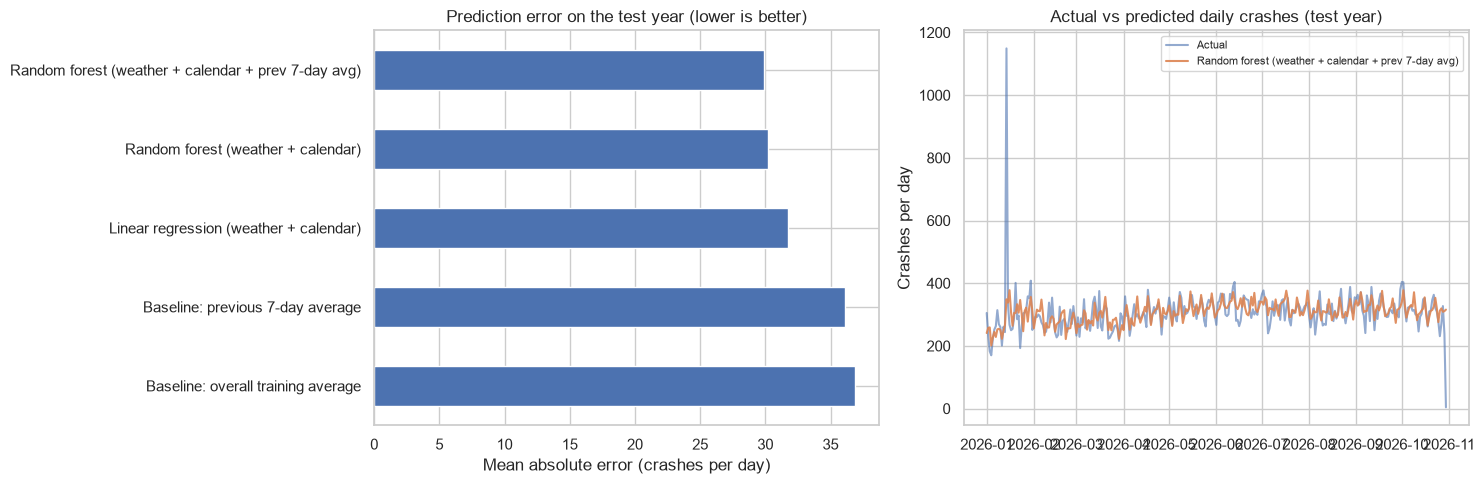

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

summary["MAE (crashes/day)"].sort_values(ascending=False).plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Prediction error on the test year (lower is better)")
axes[0].set_xlabel("Mean absolute error (crashes per day)")

best = summary.index[0] if not summary.index[0].startswith("Baseline") else summary.index[~summary.index.str.startswith("Baseline")][0]
axes[1].plot(test.index, test["crashes"], label="Actual", alpha=0.6)
axes[1].plot(test.index, preds[best], label=best, alpha=0.9)
axes[1].set_title("Actual vs predicted daily crashes (test year)")
axes[1].set_ylabel("Crashes per day")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

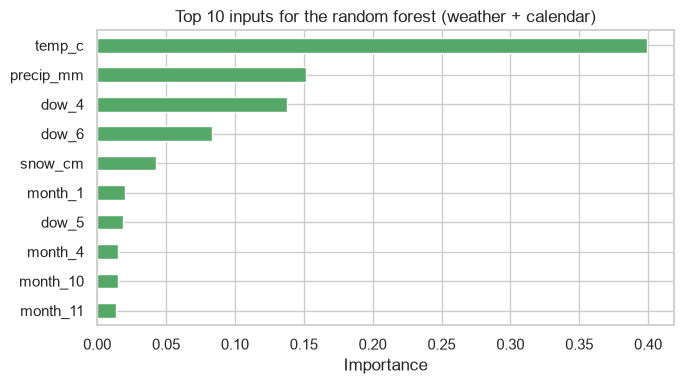

In [44]:
# Which inputs did the weather + calendar random forest rely on most?
imp = pd.Series(rf.feature_importances_, index=X_tr.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot.barh(figsize=(7, 4), color="#55A868")
plt.title("Top 10 inputs for the random forest (weather + calendar)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 7. Viz 3: crashes and severity by weather condition

This tests **H3: bad weather raises crash counts but not severity.**
- Left: number of crashes recorded under each condition.
- Right: percent of those crashes that were severe, with the overall rate as a dashed line.

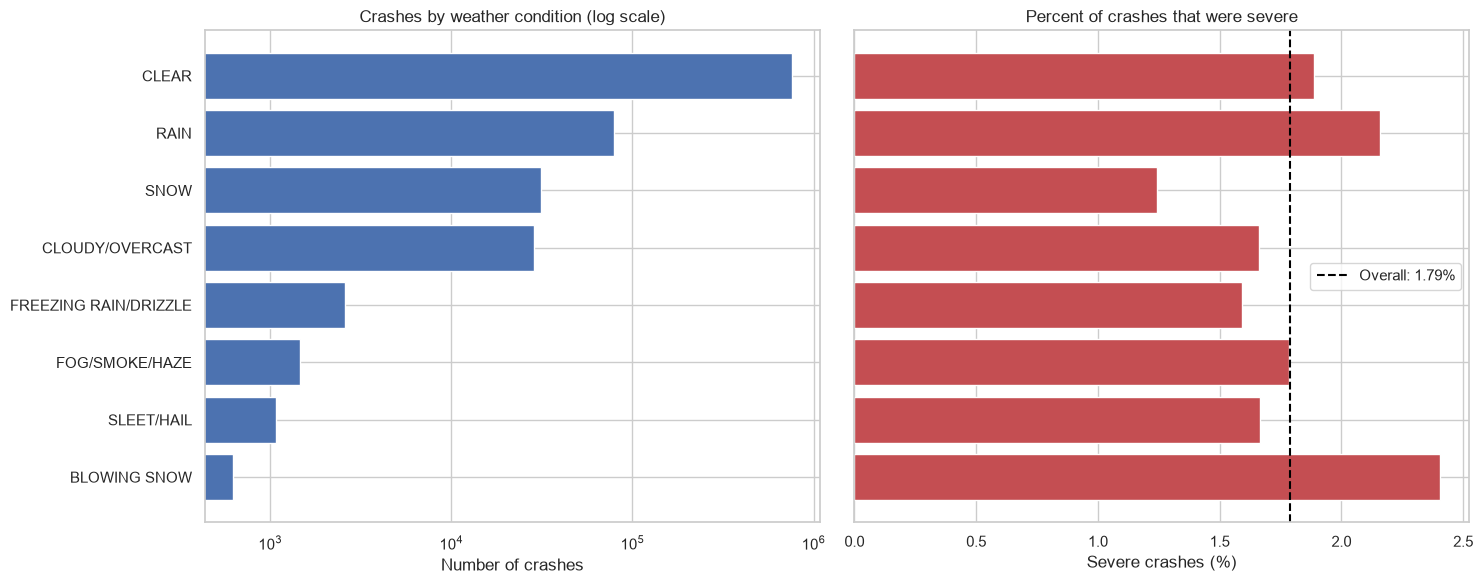

,crashes,severe_pct
weather_condition,,
BLOWING SNOW,624,2.40
SLEET/HAIL,1081,1.67
FOG/SMOKE/HAZE,1457,1.78
FREEZING RAIN/DRIZZLE,2573,1.59
CLOUDY/OVERCAST,28633,1.66
SNOW,31366,1.24
RAIN,78651,2.16
CLEAR,758351,1.89


In [45]:
w = df.copy()
w["weather_condition"] = w["weather_condition"].astype(str).str.upper().str.strip()
w = w[~w["weather_condition"].isin(["UNKNOWN", "OTHER", "NAN", ""])]

by_wx = (w.groupby("weather_condition")
           .agg(crashes=("severe", "size"), severe_pct=("severe", lambda s: s.mean() * 100))
           .query("crashes >= 300")                       # drop very rare conditions
           .sort_values("crashes"))
overall = w["severe"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)
axes[0].barh(by_wx.index, by_wx["crashes"], color="#4C72B0")
axes[0].set_xscale("log")
axes[0].set_title("Crashes by weather condition (log scale)")
axes[0].set_xlabel("Number of crashes")

axes[1].barh(by_wx.index, by_wx["severe_pct"], color="#C44E52")
axes[1].axvline(overall, color="black", linestyle="--", label=f"Overall: {overall:.2f}%")
axes[1].set_title("Percent of crashes that were severe")
axes[1].set_xlabel("Severe crashes (%)")
axes[1].legend()
plt.tight_layout()
plt.show()
by_wx.round(2)

The chart above counts crashes, and most days are clear, so clear weather will always have the most crashes. A fairer test of "does bad weather raise crash counts" is to compare the **average crashes per day** on dry, rainy, and snowy days:

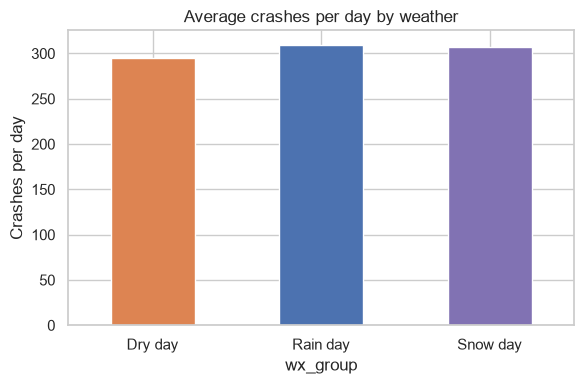

,avg crashes per day,days
wx_group,,
Dry day,294.9,2024
Rain day,309.9,968
Snow day,306.7,226


In [46]:
def weather_group(row):
    if row["snow_cm"] >= 0.5:
        return "Snow day"
    if row["precip_mm"] >= 1:
        return "Rain day"
    return "Dry day"

data["wx_group"] = data.apply(weather_group, axis=1)
per_day = data.groupby("wx_group")["crashes"].agg(["mean", "count"]).rename(columns={"mean": "avg crashes per day", "count": "days"})
per_day = per_day.reindex(["Dry day", "Rain day", "Snow day"])

per_day["avg crashes per day"].plot.bar(color=["#DD8452", "#4C72B0", "#8172B3"], figsize=(6, 4), rot=0)
plt.title("Average crashes per day by weather")
plt.ylabel("Crashes per day")
plt.tight_layout()
plt.show()
per_day.round(1)

## 8. Findings (fill in after running, in plain language)

What I did:
I joined daily Chicago weather data (temperature, rain, snow) with daily crash counts and trained models to predict how many crashes occur each day, testing on the most recent year.

ML 2:
We wanted to see whether weather and the calendar could predict how many crashes Chicago would have on a given day. We trained on earlier years and tested on 2026, where the average day has about 306 crashes. Guessing “same as the last 7 days” was off by about 36 crashes a day. Our best model, a random forest using weather, the calendar, and the previous 7-day average, was off by about 30. The version with only weather and calendar features did almost as well (30.2), and adding the recent crash level improved things by only about 0.3 crashes per day. So weather and calendar information beats the simple baseline on its own, though the model still misses by roughly 10% of a typical day, so it’s useful but not precise.

Viz 3:
We found that severe crash rates varied by weather condition, from 1.24% in snow to 2.40% in blowing snow, around an overall rate of 1.79%. Bad weather did bring more crashes per day: rain days averaged about 310 and snow days about 307, compared with about 295 on dry days.

What this means for H3:
H3 holds up for crash counts, but only barely. Rain and snow days had roughly 4-5% more crashes than dry days, a small bump. Severity doesn’t follow the same pattern: snow was below the overall severe rate, and rain was only slightly above it. So bad weather nudges up the number of crashes, but it doesn’t consistently make them worse.

**Limits:** Weather data comes from a single point (O'Hare) for the whole city; the weather condition column is the officer's description at the time of the crash; and I used real weather as input, not a forecast.